<a href="https://colab.research.google.com/github/Dani-ela-git/Visualization-Data/blob/main/DataVisualization.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Trabalho de Viualização Computacional 2026

Integrantes:


*   Daniela Costa da Silva 14613625
*   Isaac Ferreira Souza Santos 15637912
*   Thiago Santos ...
*   Luka ...

<a id="1- Importação das bibliotecas"></a>
## 1. BIBLIOTECAS

Importando as bibliotecas necessárias para as análises

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from scipy.stats import spearmanr

<a id="2- Importação do dataset"></a>
## 2. IMPORTAÇÃO DO DATASET

Importando dataset do repositório no GitHub.

Aqui vale explicar:


*   A coluna Tabela de Origem representa os departamentos no dataset.
*   As colunas Documentos Total na Consulta e Citações Totais representam a quantidade de artigos publicados no total por esse pesquisador naquele ano e as citações totais do mesmo, respectivamente.
*   O Índice H mostra o equilibrio entre produtividade e o impacto, ou seja, um pesquisador tem índice h = 30 se ele tiver 30 artigos citados pelo menos 30 vezes.
*  O Índice i10 representa quantos artigos aquele pesquisador pubicou que foram citados mais de 10 vezes.



In [3]:
url = "https://raw.githubusercontent.com/Dani-ela-git/Visualization-Data/refs/heads/main/dataset.csv"
df = pd.read_csv(url)
df.head(5)

,ano,numero usp,nome do pesquisador,identificador do google scholar,documentos total na consulta,citações totais,índice h,índice i10,data da consulta,tabela de origem
0,2015,3039263.0,Adenilso da Silva Simão,gdT5wnMAAAAJ,239.0,2166.0,26.0,66.0,2026-10-22,SSC
1,2015,235343.0,Alexandre Cláudio Botazzo Delbem,d6joXYMAAAAJ,439.0,4423.0,32.0,109.0,2026-10-22,SSC
2,2015,7331194.0,Cláudio Fabiano Motta Toledo,oiW7E1IAAAAJ,196.0,2181.0,22.0,53.0,2026-10-22,SSC
3,2015,3258581.0,Denis Fernando Wolf,ncy_2xUAAAAJ,257.0,5410.0,34.0,90.0,2026-10-22,SSC
4,2015,51108.0,Edson dos Santos Moreira,QisD2NoAAAAJ,261.0,1248.0,18.0,37.0,2026-10-22,SSC


<a id="4-Tratamento de dados"></a>
## 3. TRATAMENTO DE DADOS

Tratamento de dados para serem utilizados depois.



Anos por pesquisador:
 count    162.000000
mean       8.271605
std        3.596107
min        1.000000
25%        5.000000
50%       11.000000
75%       11.000000
max       11.000000
Name: ano, dtype: float64

--- Resumo por Departamento ---
  tabela de origem  n_pesquisadores  docs_total  citacoes_total    h_medio  \
0              SCC               36      7953.0        129727.0  24.083333   
2              SME               41      6244.0         97755.0  19.048780   
3              SSC               29      6740.0         88196.0  24.344828   
1              SMA               56      3161.0         27086.0  10.142857   

   h_max  i10_total  citacoes_por_pesq  docs_por_pesq  citacoes_por_doc  
0   46.0     2131.0        3603.527778     220.916667         16.311706  
2   78.0     1648.0        2384.268293     152.292683         15.655830  
3   52.0     1808.0        3041.241379     232.413793         13.085460  
1   40.0      687.0         483.678571      56.446429          8.568807

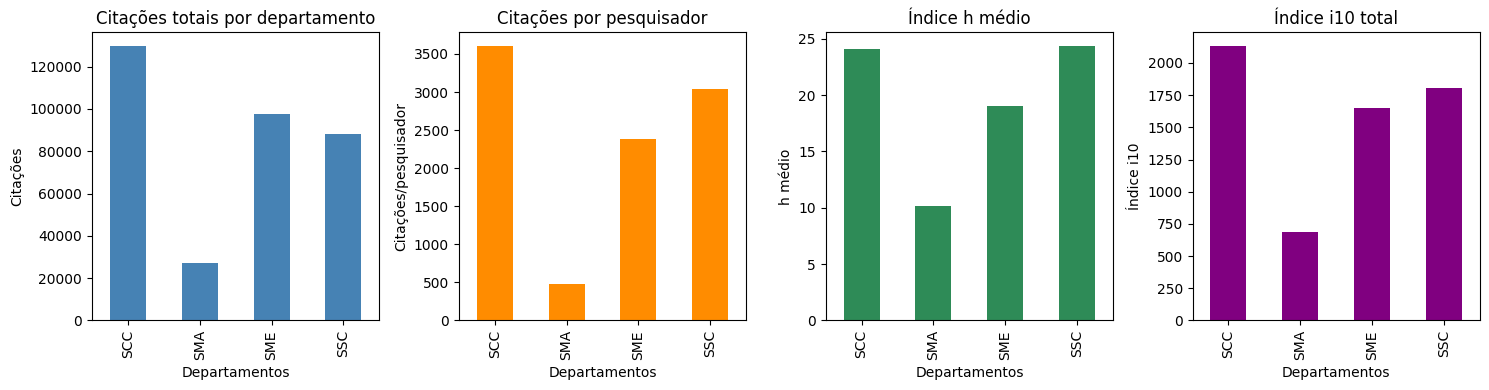

In [51]:
# limpeza inicial para o Spearman não dar NaN
colunas_numericas = [
    'ano', 'documentos total na consulta', 'citações totais',
    'índice h', 'índice i10'
]

for col in colunas_numericas:
    # Transforma em número, o que não for número vira NaN (coerce)
    df[col] = pd.to_numeric(df[col], errors='coerce')

# Remove linhas onde as métricas principais estão vazias
df = df.dropna(subset=['nome do pesquisador', 'documentos total na consulta', 'citações totais'])

# verifica duplicatas
print("Anos por pesquisador:\n", df.groupby('nome do pesquisador')['ano'].nunique().describe())

# pega o registro mais recente do pesquisador
df_ultimo = df.sort_values('ano').groupby('nome do pesquisador', as_index=False).last()

# agrega por departamento (Para a Análise 1)
resumo = df_ultimo.groupby('tabela de origem').agg(
    n_pesquisadores=('nome do pesquisador', 'nunique'),
    docs_total=('documentos total na consulta', 'sum'),
    citacoes_total=('citações totais', 'sum'),
    h_medio=('índice h', 'mean'),
    h_max=('índice h', 'max'),
    i10_total=('índice i10', 'sum'),
).reset_index()

# Métricas normalizadas (impacto por pesquisador)
resumo['citacoes_por_pesq'] = resumo['citacoes_total'] / resumo['n_pesquisadores']
resumo['docs_por_pesq'] = resumo['docs_total'] / resumo['n_pesquisadores']
resumo['citacoes_por_doc'] = resumo['citacoes_total'] / resumo['docs_total']

print("\n--- Resumo por Departamento ---")
print(resumo.sort_values('citacoes_total', ascending=False))

#----------------------------------------------- VISUALIZAÇÃO COMPARATIVA-----------------------------------

fig, axes = plt.subplots(1, 4, figsize=(15, 4))

resumo.plot(x='tabela de origem', y='citacoes_total', kind='bar', ax=axes[0], legend=False, color='steelblue')
axes[0].set_title('Citações totais por departamento')
axes[0].set_ylabel('Citações')
axes[0].set_xlabel('Departamentos')

resumo.plot(x='tabela de origem', y='citacoes_por_pesq', kind='bar', ax=axes[1], legend=False, color='darkorange')
axes[1].set_title('Citações por pesquisador')
axes[1].set_ylabel('Citações/pesquisador')
axes[1].set_xlabel('Departamentos')

resumo.plot(x='tabela de origem', y='h_medio', kind='bar', ax=axes[2], legend=False, color='seagreen')
axes[2].set_title('Índice h médio')
axes[2].set_ylabel('h médio')
axes[2].set_xlabel('Departamentos')

resumo.plot(x='tabela de origem', y='i10_total', kind='bar', ax=axes[3], legend=False, color='purple')
axes[3].set_title('Índice i10 total')
axes[3].set_ylabel('Índice i10')
axes[3].set_xlabel('Departamentos')

plt.tight_layout()
plt.show()

<a id="4-Análise 1"></a>
## 4. Análise 1: qual departamento possui maior impacto científico?

Primeira análise feita no dataset é qual departamento do ICMC tem maior impcto científico.

A ideia nessa análise é: usar um boxplot para mostrar a mediana, quartis e outliers. Dessa forma, garantimos robustez mais do que se usarmos apenas a média, uma vez que não fica distorcido por valores extremos.

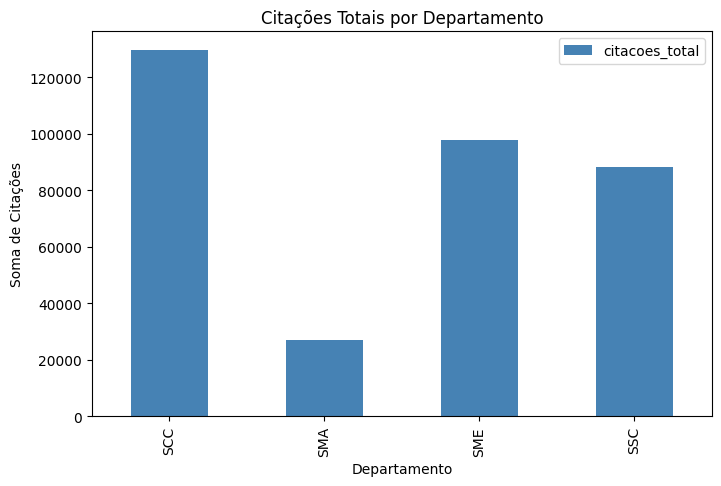

/tmp/ipykernel_1963/1286878944.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_ultimo, x='tabela de origem', y=m, palette='Set2')


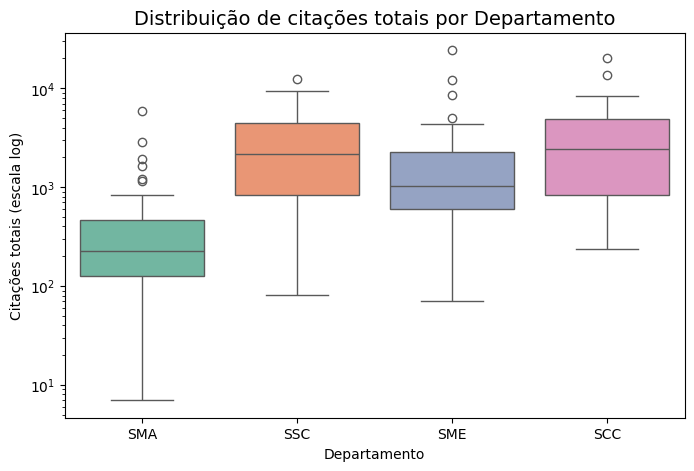

Medianas para citações totais (por pesquisador único):
tabela de origem
SCC    2412.5
SMA     223.5
SME    1022.0
SSC    2166.0
Name: citações totais, dtype: float64
----------------------------------------


/tmp/ipykernel_1963/1286878944.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_ultimo, x='tabela de origem', y=m, palette='Set2')


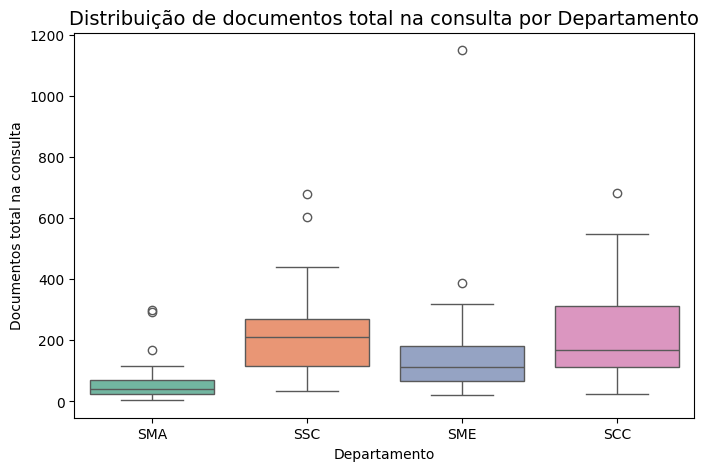

Medianas para documentos total na consulta (por pesquisador único):
tabela de origem
SCC    168.5
SMA     41.5
SME    112.0
SSC    212.0
Name: documentos total na consulta, dtype: float64
----------------------------------------


/tmp/ipykernel_1963/1286878944.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_ultimo, x='tabela de origem', y=m, palette='Set2')


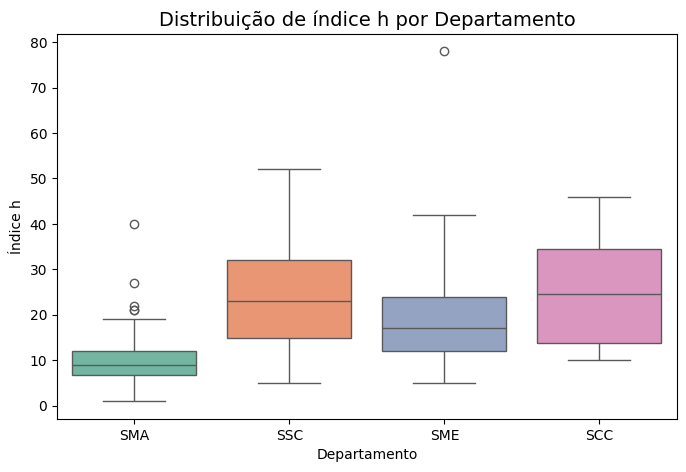

Medianas para índice h (por pesquisador único):
tabela de origem
SCC    24.5
SMA     9.0
SME    17.0
SSC    23.0
Name: índice h, dtype: float64
----------------------------------------


/tmp/ipykernel_1963/1286878944.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_ultimo, x='tabela de origem', y=m, palette='Set2')


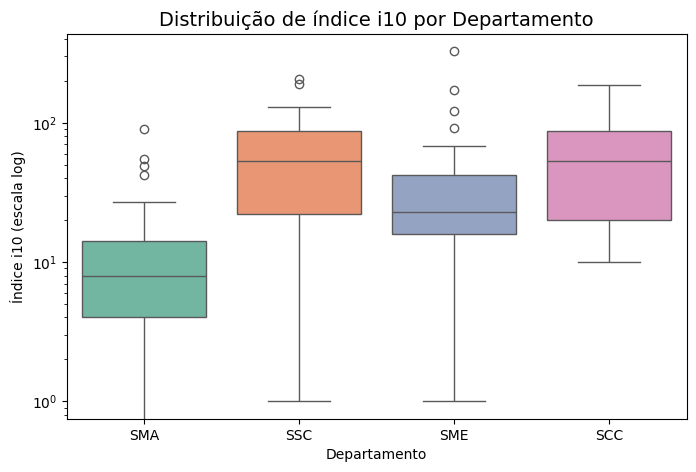

Medianas para índice i10 (por pesquisador único):
tabela de origem
SCC    53.5
SMA     8.0
SME    23.0
SSC    53.0
Name: índice i10, dtype: float64
----------------------------------------


In [52]:
# @title
#grafico de barras com as citações totais
resumo.plot(x='tabela de origem', y='citacoes_total', kind='bar', color='steelblue', figsize=(8,5))
plt.title('Citações Totais por Departamento')
plt.ylabel('Soma de Citações')
plt.xlabel('Departamento')
plt.show()

metricas = ['citações totais', 'documentos total na consulta', 'índice h', 'índice i10']
for m in metricas:
  plt.figure(figsize=(8, 5))
  sns.boxplot(data=df_ultimo, x='tabela de origem', y=m, palette='Set2')
  plt.title(f'Distribuição de {m} por Departamento', fontsize=14)
  plt.ylabel(m.capitalize())
  plt.xlabel('Departamento')

  #aplicando escala logaritmica no eixo y
  if m in ['citações totais', 'índice i10']:
        plt.yscale('log')
        plt.ylabel(f'{m.capitalize()} (escala log)')

  plt.show()

  # Mostra as medianas calculadas
  print(f"Medianas para {m} (por pesquisador único):")
  print(df_ultimo.groupby('tabela de origem')[m].median())
  print('-' * 40)

  plt.show()


<a id="5-Análise 2"></a>
## 5. Análise 2: produzir mais documentos significa receber mais citações?

Essa análise pode revelar que pesquisadores com poucos artigos publicados podem ter grandes impactos. Aqui, usamos um gráfico de disperção entre documentos e citações e também calculamos a correlação de Spearman.

In [ ]:
rho, p = spearmanr(df_ultimo['documentos total na consulta'], df_ultimo['citações totais'])
print(f"Spearman ρ = {rho:.3f} | p-valor = {p:.2e}")

plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=df_ultimo,
    x='documentos total na consulta',
    y='citações totais',
    hue='tabela de origem',
    alpha=0.7,
    edgecolor='none'
)
plt.title(f'Documentos × Citações (Spearman ρ = {rho:.2f}, p = {p:.1e})')
plt.xlabel('Documentos totais')
plt.ylabel('Citações totais')
plt.legend(title='Departamento', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

# Razão citações/documentos (para achar outliers de eficiência)
df_ultimo['cit_por_doc'] = (
    df_ultimo['citações totais'] / df_ultimo['documentos total na consulta']
)

<a id="6-Análise 3"></a>
## 6. Análise 3: quais pesquisadores apresentam maior impacto por departamento?

                                nome do pesquisador tabela de origem  \
130         Ricardo José Gabrielli Barreto Campello              SCC   
62   Gustavo Enrique de Almeida Prado Alves Batista              SCC   
38                            Eduardo Raul Hruschka              SCC   
53                    Francisco Aparecido Rodrigues              SME   
31                            Diego Raphael Amancio              SCC   
153                      Thomas Klaus DalMaso Peron              SME   
91                                         Ma To Fu              SMA   
30                              Diego Furtado Silva              SCC   
154                          Tiago Pereira da Silva              SME   
140                                  Rosane Minghim              SCC   

     documentos total na consulta  citações totais  cit_por_doc  
130                         146.0          13491.0    92.404110  
62                          332.0          20058.0    60.415663  
38       

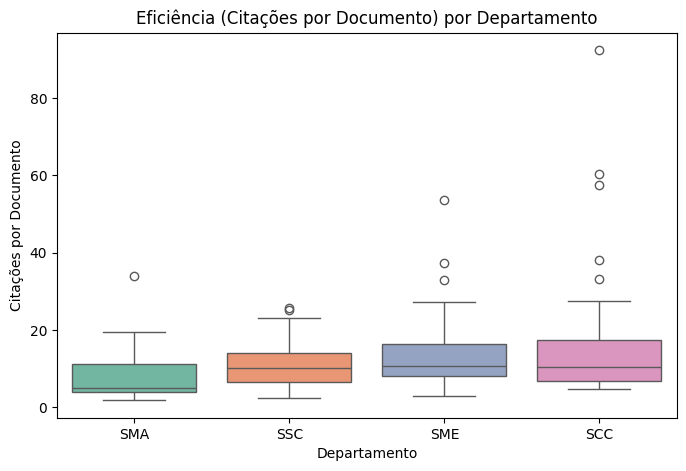

In [41]:
#filtrar pesquisadores com no mínimo 30 artigos para fazer sentido na métrica
df_filtrado = df_ultimo[df_ultimo['documentos total na consulta'] >= 30].copy()

# pegando o top 10
top10_eficientes = df_filtrado.nlargest(10, 'cit_por_doc')

# mostrar a tabela com Nome, Departamento e a Razão
print(top10_eficientes[['nome do pesquisador', 'tabela de origem', 'documentos total na consulta', 'citações totais', 'cit_por_doc']])

# Calculando a mediana de eficiência por departamento
mediana_eficiencia = df_filtrado.groupby('tabela de origem')['cit_por_doc'].median().sort_values(ascending=False)
print(mediana_eficiencia)

#plotando
plt.figure(figsize=(8, 5))
sns.boxplot(data=df_filtrado, x='tabela de origem', y='cit_por_doc', hue = 'tabela de origem', palette='Set2', legend=False)
plt.title('Eficiência (Citações por Documento) por Departamento')
plt.ylabel('Citações por Documento')
plt.xlabel('Departamento')
plt.show()

<a id="7-Análise 4"></a>
## 7. Análise 4: A produção científica se concentra em poucos pesquisadores?

Aqui, vamos calcular a porcentagem de citações que os 10% mais citados detêm e plotar a Curva de Lorenz. Se for muito curvada para baixo, então as citações é concntrada em poucos pesquisadores.

A curva de Lorenz plota a porcentagem acumulada da população (eixo X) contra a porcentagem acumulada de citações (eixo Y). Para isso, precisamos ordenar do menos citado para o mais citado.

Vamos mostrar também o Indice de Gini. O Gini resume a curva em um número: 0 é igualdade total, 1 é concentração total.

Os 16 pesquisadores mais citados (10%) concentram 46.25% de todas as citações.
Índice de Gini: 0.649


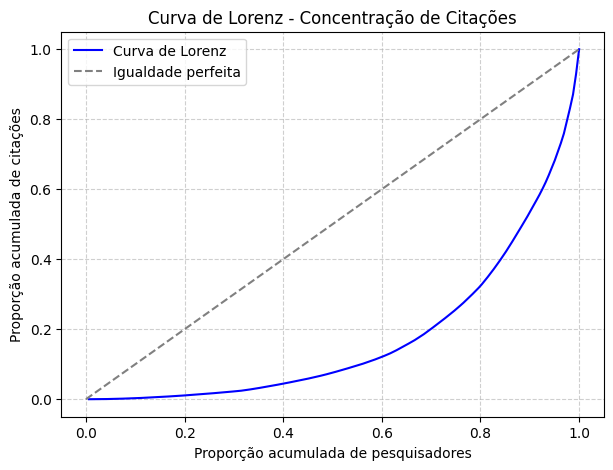

In [47]:
#ordenando os pesquisadores com base nas citações
df_cit = df_ultimo.sort_values('citações totais', ascending=False).copy()

#descobrindo quanto é 10% deles
n_top10 = int(len(df_cit) * 0.10)

#somando as citações do top 10%
citacoes_top10 = df_cit.head(n_top10)['citações totais'].sum()
citacoes_total = df_cit['citações totais'].sum()

#calculando a porcentagem
porcentagem = (citacoes_top10 / citacoes_total) * 100
print(f"Os {n_top10} pesquisadores mais citados (10%) concentram {porcentagem:.2f}% de todas as citações.")

#curvas de Lorenz
# Ordenar do menor para o maior
cit_asc = df_ultimo['citações totais'].sort_values().values

# Calcular os acumulados
cum_cit = np.cumsum(cit_asc) / sum(cit_asc)
cum_pop = np.arange(1, len(cit_asc) + 1) / len(cit_asc)

# Fórmula do Gini
def gini(array):
    array = np.sort(array)
    n = len(array)
    index = np.arange(1, n + 1)
    return (np.sum((2 * index - n - 1) * array)) / (n * np.sum(array))

g = gini(cit_asc)
print(f"Índice de Gini: {g:.3f}")

# Plotar
plt.figure(figsize=(7, 5))
plt.plot(cum_pop, cum_cit, label='Curva de Lorenz', color='blue')
plt.plot([0, 1], [0, 1], '--', color='gray', label='Igualdade perfeita')
plt.title('Curva de Lorenz - Concentração de Citações')
plt.xlabel('Proporção acumulada de pesquisadores')
plt.ylabel('Proporção acumulada de citações')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

<a id="8-Análise 5"></a>
## 8. Análise 5: Quantos pesquisadores entraram e quantos sairam nos ultimos 10 anos em cada departamento?

Aqui preciamos definir quem entrou e saiu ao decorrer dos anos. Quem entrou deve ter sua primeira data de publicação depois de 2016, pois não estava em 2015 e quem saiu deve ter sua ultima data de publicação até 2024, pois não estava em 2026.

Aqui talvez explique porque o SMA tem menos citações e desempenho inferior no impacto de produção científica.

                  entraram  sairam  saldo_liquido
tabela de origem                                 
SCC                     10      13             -3
SMA                     12      18             -6
SME                      5       6             -1
SSC                      5       7             -2


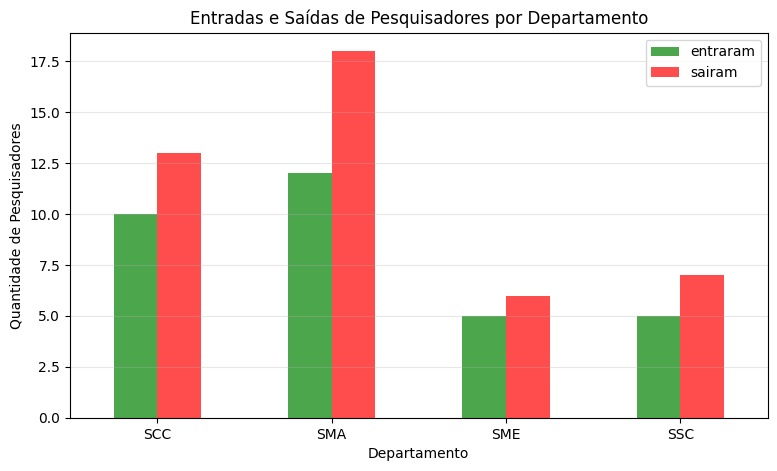

In [48]:
# Pega o primeiro e o último ano de cada pesquisador em cada departamento
historico_pesq = df.groupby(['nome do pesquisador', 'tabela de origem'])['ano'].agg(
    primeiro_ano='min',
    ultimo_ano='max'
).reset_index()

# Entraram : omeçaram a aparecer de 2016 em diante
entraram = historico_pesq[historico_pesq['primeiro_ano'] >= 2016]

# Saíram: O último registro deles foi em 2024 ou antes
sairam = historico_pesq[historico_pesq['ultimo_ano'] <= 2024]

# Contagem por departamento
contagem_entradas = entraram.groupby('tabela de origem').size().rename('entraram')
contagem_saidas = sairam.groupby('tabela de origem').size().rename('sairam')

# Juntar em uma tabela só
fluxo_depto = pd.concat([contagem_entradas, contagem_saidas], axis=1).fillna(0)

# Calcular o saldo (entradas - saídas)
fluxo_depto['saldo_liquido'] = fluxo_depto['entraram'] - fluxo_depto['sairam']

print(fluxo_depto)

# grafico de barras agrupadas
fluxo_depto[['entraram', 'sairam']].plot(
    kind='bar',
    figsize=(9, 5),
    color=['green', 'red'],
    alpha=0.7
)
plt.title('Entradas e Saídas de Pesquisadores por Departamento')
plt.xlabel('Departamento')
plt.ylabel('Quantidade de Pesquisadores')
plt.xticks(rotation=0)
plt.grid(axis='y', alpha=0.3)
plt.show()